In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt  
import seaborn as sns 

In [2]:
df=pd.read_csv('ml_macs_project.csv')
df.drop(columns=['date','store_id','is_weekend','product_id','establishment_year','launch_year','revenue','customer_gender','subcategory'], axis=1,inplace=True)
df.sample(5)

,day_of_week,month,quarter,is_holiday,region,store_type,city,store_size_sqft,parking_available,competition_distance,...,customer_footfall,stock_level,stock_out,temperature_celsius,economic_index,inflation_rate,sales_quantity,price_weight_ratio,customer_value_score,seasonal_score
351480,Saturday,9,3,0,Central,Highway,Kolkata,5931,0,1846.05,...,195,178,0,24.7,99.5,5.7,0.0,NaN,20.38400,1.0
464981,Monday,12,4,0,North,Mall,Kolkata,5033,1,1971.74,...,122,31,0,13.6,91.4,5.2,2.0,949.504065,11.82132,1.4
153919,Wednesday,4,2,0,West,Mall,Mumbai,7233,1,543.14,...,127,316,0,37.6,98.0,9.3,6.0,34.360360,NaN,1.3
402557,Wednesday,11,4,0,Central,Residential,Delhi,14919,0,-896.19,...,102,412,0,29.2,108.3,6.0,6.0,284.975265,43.41492,1.6
833029,Tuesday,9,3,0,East,Airport,Hyderabad,14324,1,645.41,...,89,78,0,26.3,105.3,11.2,2.0,2718.357542,11.29320,1.0


In [3]:
columns_names=df.columns
print(columns_names)

Index(['day_of_week', 'month', 'quarter', 'is_holiday', 'region', 'store_type',
       'city', 'store_size_sqft', 'parking_available', 'competition_distance',
       'competitor_count', 'store_rating', 'staff_count', 'category',
       'base_price', 'actual_price', 'brand_tier', 'weight_kg', 'returnable',
       'warranty_months', 'customer_age', 'customer_income',
       'discount_percent', 'promotion_active', 'marketing_spend',
       'customer_footfall', 'stock_level', 'stock_out', 'temperature_celsius',
       'economic_index', 'inflation_rate', 'sales_quantity',
       'price_weight_ratio', 'customer_value_score', 'seasonal_score'],
      dtype='object')


In [4]:
df.shape

(900000, 35)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900000 entries, 0 to 899999
Data columns (total 35 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   day_of_week           900000 non-null  object 
 1   month                 900000 non-null  int64  
 2   quarter               900000 non-null  int64  
 3   is_holiday            900000 non-null  int64  
 4   region                900000 non-null  object 
 5   store_type            900000 non-null  object 
 6   city                  900000 non-null  object 
 7   store_size_sqft       900000 non-null  int64  
 8   parking_available     900000 non-null  int64  
 9   competition_distance  845974 non-null  float64
 10  competitor_count      900000 non-null  int64  
 11  store_rating          845880 non-null  float64
 12  staff_count           900000 non-null  int64  
 13  category              900000 non-null  object 
 14  base_price            900000 non-null  float64
 15  

In [6]:
df.isnull().sum()

day_of_week                  0
month                        0
quarter                      0
is_holiday                   0
region                       0
store_type                   0
city                         0
store_size_sqft              0
parking_available            0
competition_distance     54026
competitor_count             0
store_rating             54120
staff_count                  0
category                     0
base_price                   0
actual_price                 0
brand_tier                   0
weight_kg                53880
returnable                   0
warranty_months              0
customer_age             46585
customer_income          46584
discount_percent             0
promotion_active             0
marketing_spend          54015
customer_footfall            0
stock_level                  0
stock_out                    0
temperature_celsius      72036
economic_index          107803
inflation_rate               0
sales_quantity               0
price_we

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
x=df.drop(columns=['sales_quantity'],axis=1)
y=df['sales_quantity']

In [9]:
x.iloc[:,15:]

,actual_price,brand_tier,weight_kg,returnable,warranty_months,customer_age,customer_income,discount_percent,promotion_active,marketing_spend,customer_footfall,stock_level,stock_out,temperature_celsius,economic_index,inflation_rate,price_weight_ratio,customer_value_score,seasonal_score
0,52.26,Mid,1.52,1,6,18.0,53355.0,20.4,1,NaN,126,182,0,20.7,80.0,9.5,34.381579,19.20780,0.8
1,862.32,Mid,6.41,1,0,59.0,59742.0,0.0,0,NaN,165,357,0,16.3,103.7,4.5,134.527301,70.49556,0.8
2,6628.95,Mid,0.33,1,6,28.0,65418.0,0.0,0,1225.72,195,346,0,22.6,NaN,10.1,20087.727273,36.63408,0.8
3,396.37,Premium,0.25,0,0,46.0,51047.0,20.6,1,NaN,153,43,0,17.0,122.4,7.8,1585.480000,46.96324,0.8
4,527.31,Budget,0.85,1,0,18.0,33731.0,0.0,0,1358.00,130,37,0,NaN,NaN,5.0,620.364706,12.14316,0.8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
899995,853.27,Mid,1.02,1,6,39.0,89985.0,0.0,0,1863.53,96,142,0,18.9,NaN,6.3,836.539216,70.18830,1.6
899996,1490.46,Mid,0.72,1,0,22.0,28415.0,0.0,0,1213.51,98,483,0,8.4,94.9,4.5,2070.083333,12.50260,1.6
899997,3727.05,Mid,5.87,1,6,NaN,61592.0,22.3,1,2876.82,83,454,0,21.8,97.0,5.3,634.931857,NaN,1.6
899998,9879.11,Mid,0.28,0,24,35.0,21004.0,0.0,0,1114.64,252,498,0,26.6,107.8,5.9,35282.535714,14.70280,1.6


<Axes: ylabel='count'>

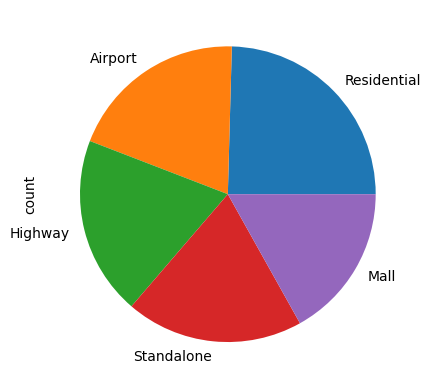

In [10]:
x['store_type'].value_counts().plot(kind='pie')

In [11]:
# x['subcategory'].value_counts().plot(kind='pie')

<Axes: ylabel='count'>

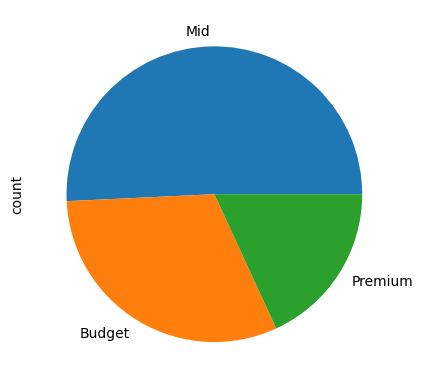

In [12]:
x['brand_tier'].value_counts().plot(kind='pie')

so there is no duplication

encoding categorical data 

In [34]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
transformer=ColumnTransformer(transformers=[
    ('trf1',SimpleImputer(strategy='median'),['competition_distance','store_rating','weight_kg','price_weight_ratio','customer_value_score','temperature_celsius','economic_index','customer_age','customer_income','marketing_spend']),
    ('trf2',OneHotEncoder(drop='first',sparse_output=False),['day_of_week','region','city','store_type','category','brand_tier'])
],remainder='passthrough')

In [35]:
x_trans=transformer.fit_transform(x)

In [36]:
x_trans

array([[1.94078e+03, 4.00000e+00, 1.52000e+00, ..., 0.00000e+00,
        9.50000e+00, 8.00000e-01],
       [1.62335e+03, 5.00000e+00, 6.41000e+00, ..., 0.00000e+00,
        4.50000e+00, 8.00000e-01],
       [1.53171e+03, 4.00000e+00, 3.30000e-01, ..., 0.00000e+00,
        1.01000e+01, 8.00000e-01],
       ...,
       [3.21134e+03, 4.30000e+00, 5.87000e+00, ..., 0.00000e+00,
        5.30000e+00, 1.60000e+00],
       [5.32734e+03, 4.30000e+00, 2.80000e-01, ..., 0.00000e+00,
        5.90000e+00, 1.60000e+00],
       [2.14393e+03, 3.70000e+00, 5.74000e+00, ..., 0.00000e+00,
        7.00000e+00, 1.60000e+00]])

In [37]:
num_cols = ['competition_distance', 'store_rating', 'weight_kg', 'price_weight_ratio', 'customer_value_score','temperature_celsius','economic_index','customer_age','customer_income','marketing_spend']
cat_cols = ['day_of_week', 'region', 'city','store_type','category','brand_tier']

getting the names of the columns of x_trans

In [38]:
encoded_cat_cols = transformer.named_transformers_['trf2'].get_feature_names_out(cat_cols)

# Get names of passthrough columns (those not in num or cat)
passthrough_cols = [col for col in x.columns if col not in num_cols + cat_cols]

# Combine all column names in correct order
final_columns = num_cols + list(encoded_cat_cols) + passthrough_cols

# --- Step 5: Convert to DataFrame ---
x_trans_df = pd.DataFrame(x_trans, columns=final_columns)

# (Optional) Reset index if needed
x_trans_df.reset_index(drop=True, inplace=True)


In [39]:
x_trans_df.shape

(900000, 60)

In [40]:
x_trans_df.iloc[:,90:94].isnull().sum()


Series([], dtype: float64)

EDA

In [41]:
from sklearn.preprocessing import MinMaxScaler
norm=MinMaxScaler()
norm.fit(x_trans_df)
x_trans_df=norm.transform(x_trans_df)

In [42]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x_trans_df,y,test_size=0.25)
y_train.info()

<class 'pandas.core.series.Series'>
Index: 675000 entries, 197033 to 635688
Series name: sales_quantity
Non-Null Count   Dtype  
--------------   -----  
675000 non-null  float64
dtypes: float64(1)
memory usage: 10.3 MB


In [43]:
# from sklearn.linear_model import LinearRegression
# lr=LinearRegression()
# lr.fit(x_train,y_train)
# y_pred=lr.predict(x_test)

from xgboost import XGBRegressor
model=XGBRegressor(n_estimators=100,learning_rate=0.1,max_depth=3)
model.fit(x_train,y_train)
y_pred_xg=model.predict(x_test)

In [44]:
from sklearn.metrics import r2_score
r2_score(y_pred_xg,y_test)

-0.15389821600324782

In [ ]:
# ----------------------------
# Step 1: Import Libraries
# ----------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor
import warnings
warnings.filterwarnings("ignore")

# ----------------------------
# Step 2: Load & Clean Data
# ----------------------------
df = pd.read_csv("ml_macs_project.csv")

# Drop columns not required (as per your earlier step)
df.drop(columns=[
    'date', 'store_id', 'is_weekend', 'product_id',
    'establishment_year', 'launch_year', 'revenue',
    'customer_gender', 'subcategory'
], axis=1, inplace=True)

# ----------------------------
# Step 3: Handle Missing Values
# ----------------------------
df.fillna(df.median(numeric_only=True), inplace=True)

# Optional: Fill missing object types with mode
for col in df.select_dtypes(include='object').columns:
    df[col].fillna(df[col].mode()[0], inplace=True)

# ----------------------------
# Step 4: Split Features & Target
# ----------------------------
X = df.drop(columns=['sales_quantity'])
y = df['sales_quantity']

# Optional: log transform y if highly skewed
# y = np.log1p(y)

# ----------------------------
# Step 5: Define Feature Types
# ----------------------------
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include='object').columns.tolist()

# ----------------------------
# Step 6: Build Preprocessing Pipeline
# ----------------------------
numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', MinMaxScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, num_cols),
    ('cat', categorical_pipeline, cat_cols)
])

# ----------------------------
# Step 7: Transform Data
# ----------------------------
X_trans = preprocessor.fit_transform(X)

# Optional: Convert to DataFrame with column names
encoded_cat_cols = preprocessor.named_transformers_['cat']['encoder'].get_feature_names_out(cat_cols)
final_columns = list(num_cols) + list(encoded_cat_cols)
X_df = pd.DataFrame(X_trans, columns=final_columns)

# ----------------------------
# Step 8: Train-Test Split
# ----------------------------
x_train, x_test, y_train, y_test = train_test_split(X_df, y, test_size=0.25, random_state=42)

# ----------------------------
# Step 9: Train XGBoost Regressor
# ----------------------------
model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

model.fit(x_train, y_train)

# ----------------------------
# Step 10: Predict & Evaluate
# ----------------------------
# y_pred = model.predict(x_test)

print("✅ Model Evaluation:")
print("R² Score       :", r2_score(y_test, y_pred))
print("MAE            :", mean_absolute_error(y_test, y_pred))
print("RMSE           :", np.sqrt(mean_squared_error(y_test, y_pred)))

# If log1p was applied on y:
y_pred = np.expm1(y_pred_log)


✅ Model Evaluation:
R² Score       : 0.5731292481733232
MAE            : 2.2349085095365036
RMSE           : 8.657738681054038


In [21]:
# sns.scatterplot(x=x_trans_df['quarter'],y=y,hue=x_trans_df['is_holiday'])

In [22]:
# sns.scatterplot(x=x_trans_df['store_type'],y=y,hue=x_trans_df['is_holiday'])

In [20]:
# sns.scatterplot(x=x_trans_df['month'],y=y,hue=x_trans_df['is_holiday'])

In [23]:
# sns.scatterplot(x=x_trans_df['discount_percent'],y=y,hue=x_trans_df['is_holiday'])

In [ ]:
# x_test=pd.read_csv('test.csv')
# x_test.drop(columns=['date','store_id','is_weekend','product_id','establishment_year','launch_year','revenue','customer_gender'], axis=1,inplace=True)
# x_test.columns

In [ ]:
# from sklearn.compose import ColumnTransformer
# from sklearn.impute import SimpleImputer
# from sklearn.preprocessing import OneHotEncoder
# transformer=ColumnTransformer(transformers=[
#     ('trf3',SimpleImputer(),['competition_distance','store_rating','weight_kg','price_weight_ratio','customer_value_score','temperature_celsius','economic_index','customer_age','customer_income','marketing_spend']),
#     ('trf4',OneHotEncoder(drop='first',sparse_output=False),['day_of_week','region','city','store_type','category','subcategory','brand_tier'])
# ],remainder='passthrough')

In [ ]:
# x_test_trans=transformer.fit_transform(x_test)

In [ ]:
# num_cols = ['competition_distance', 'store_rating', 'weight_kg', 'price_weight_ratio', 'customer_value_score']
# cat_cols = ['day_of_week', 'region', 'city','store_type','category','subcategory','brand_tier']

In [ ]:
# encoded_cat_cols = transformer.named_transformers_['trf4'].get_feature_names_out(cat_cols)

# # Get names of passthrough columns (those not in num or cat)
# passthrough_cols = [col for col in x_test.columns if col not in num_cols + cat_cols]

# # Combine all column names in correct order
# final_columns = num_cols + list(encoded_cat_cols) + passthrough_cols

# # --- Step 5: Convert to DataFrame ---
# x_test_trans_df = pd.DataFrame(x_trans, columns=final_columns)

# # (Optional) Reset index if needed
# x_test_trans_df.reset_index(drop=True, inplace=True)


In [ ]:
# x_test_trans_df.isnull().sum()

In [ ]:
# from sklearn.preprocessing import MinMaxScaler
# norm=MinMaxScaler()
# norm.fit(x_test_trans_df)
# x_test_trans_df=norm.transform(x_test_trans_df)

In [ ]:
# from sklearn.linear_model import LinearRegression
# lr=LinearRegression()
# lr.fit(x_trans_df,y)
# y_pred=lr.predict(x_test_trans_df)

In [ ]:
# from sklearn.metrics import r2_score
# r2_score(y_pred,y)